## Part 1: Data Exploration and Visualization

In [19]:
import tensorflow as tf

IMG_SIZE = (180, 180)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "Data/train",
    image_size=IMG_SIZE,
    # batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "Data/val",
    image_size=IMG_SIZE,
    # batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names
print(class_names)
print("Nombre de classes :", len(class_names))


Found 13642 files belonging to 14 classes.
Found 98 files belonging to 14 classes.
['astilbe', 'bellflower', 'black_eyed_susan', 'calendula', 'california_poppy', 'carnation', 'common_daisy', 'coreopsis', 'dandelion', 'iris', 'rose', 'sunflower', 'tulip', 'water_lily']
Nombre de classes : 14


In [2]:
import os

data_dir = "Data/train"
print("Nb images by classe :")
for class_name in class_names:
    n_images = len(os.listdir(os.path.join(data_dir, class_name)))
    print(f"{class_name}: {n_images}")

Nb images by classe :
astilbe: 726
bellflower: 872
black_eyed_susan: 986
calendula: 1011
california_poppy: 1021
carnation: 924
common_daisy: 978
coreopsis: 1035
dandelion: 1038
iris: 1041
rose: 986
sunflower: 1013
tulip: 1034
water_lily: 977


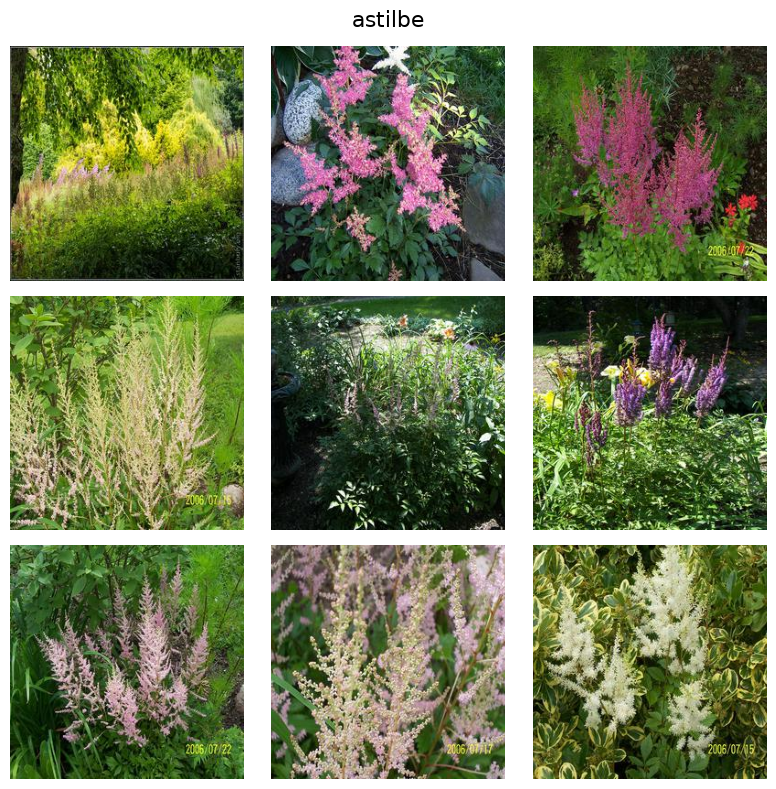

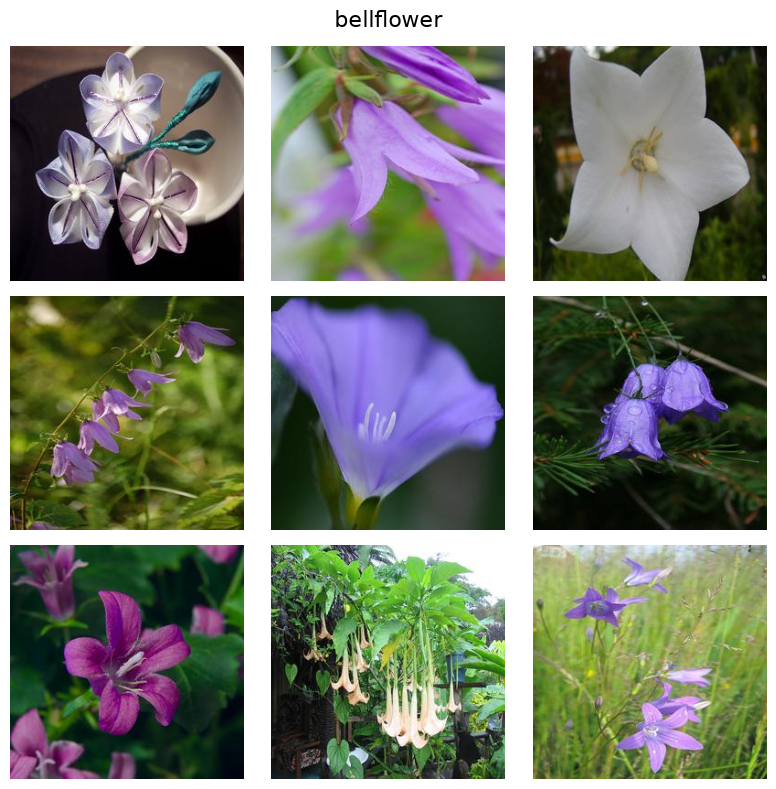

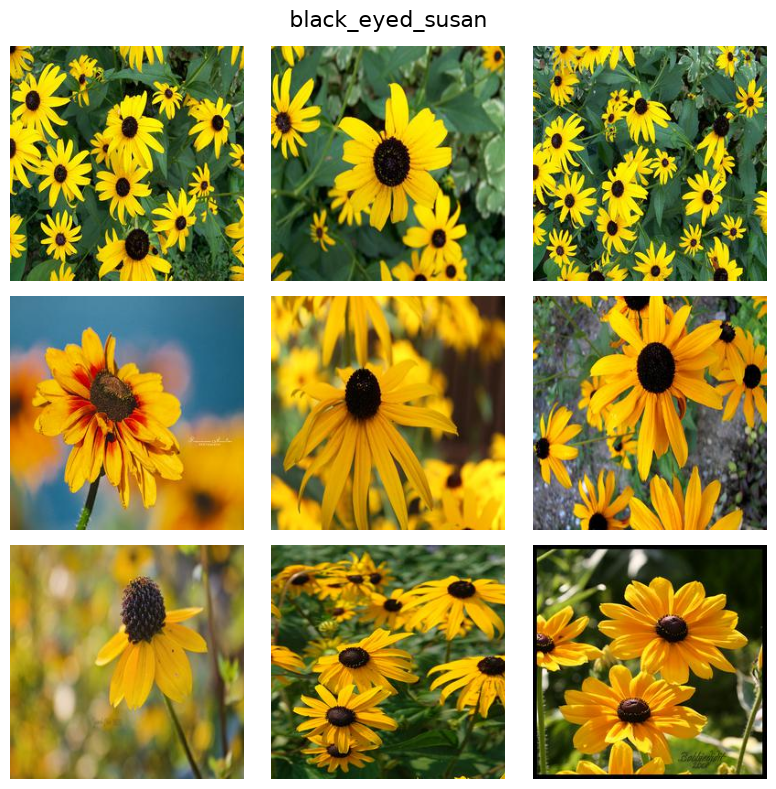

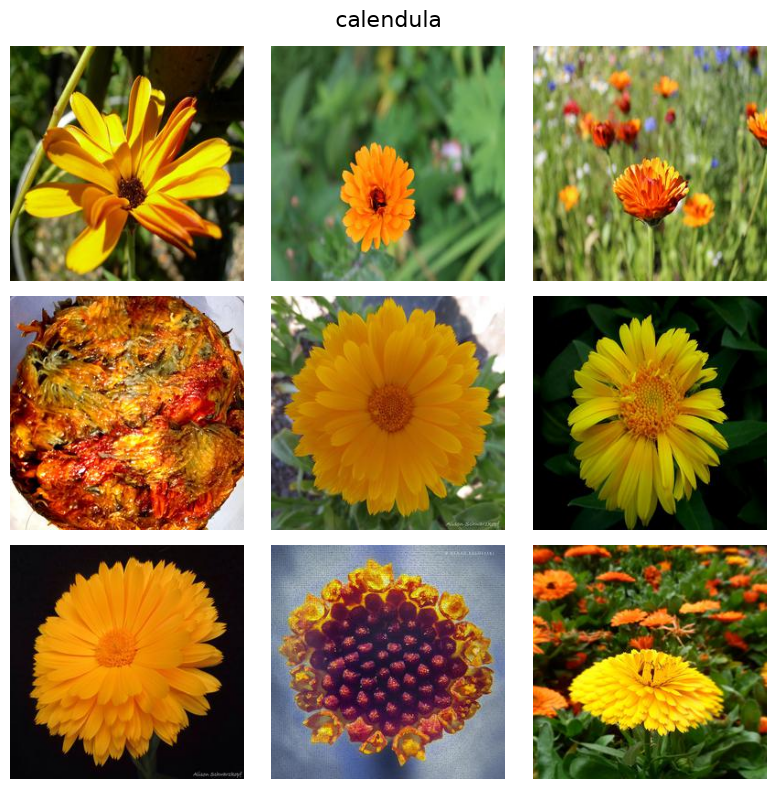

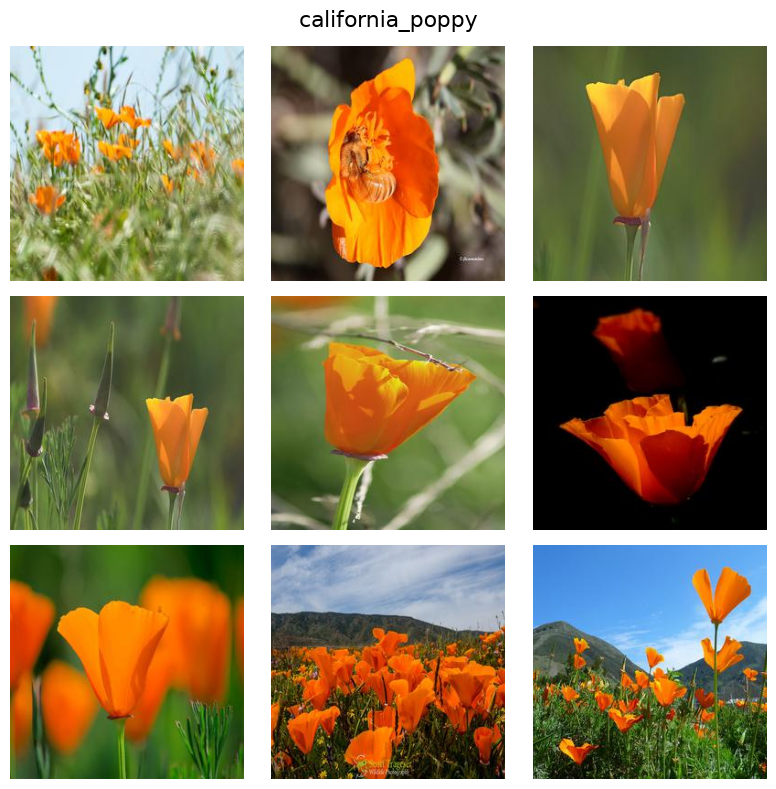

...

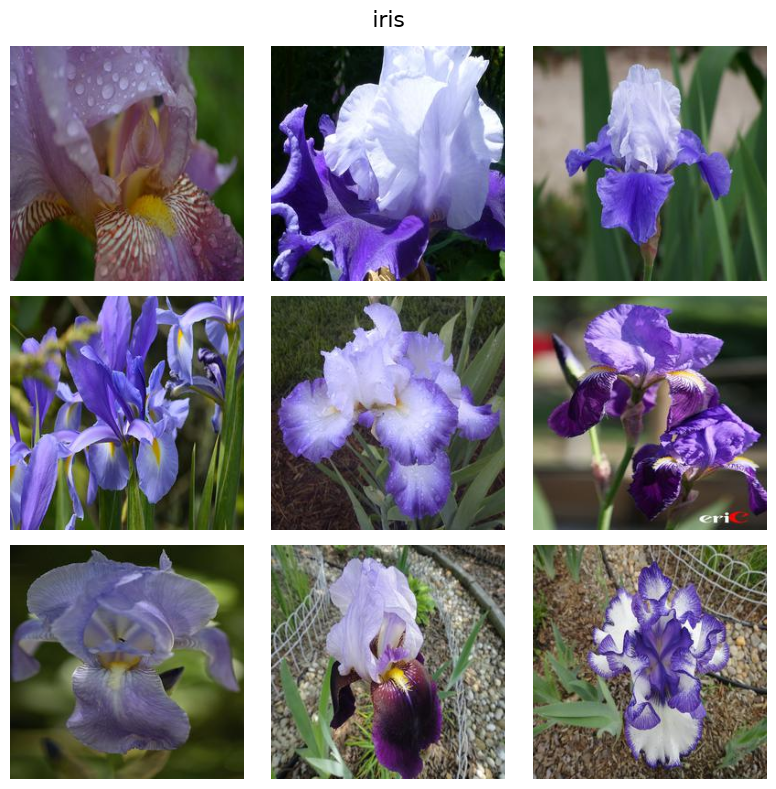

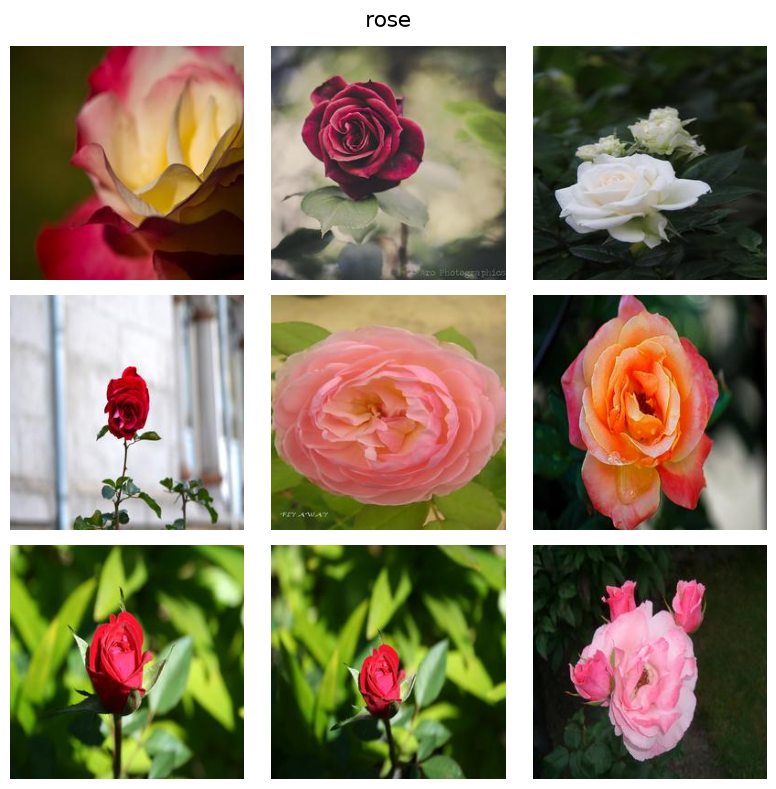

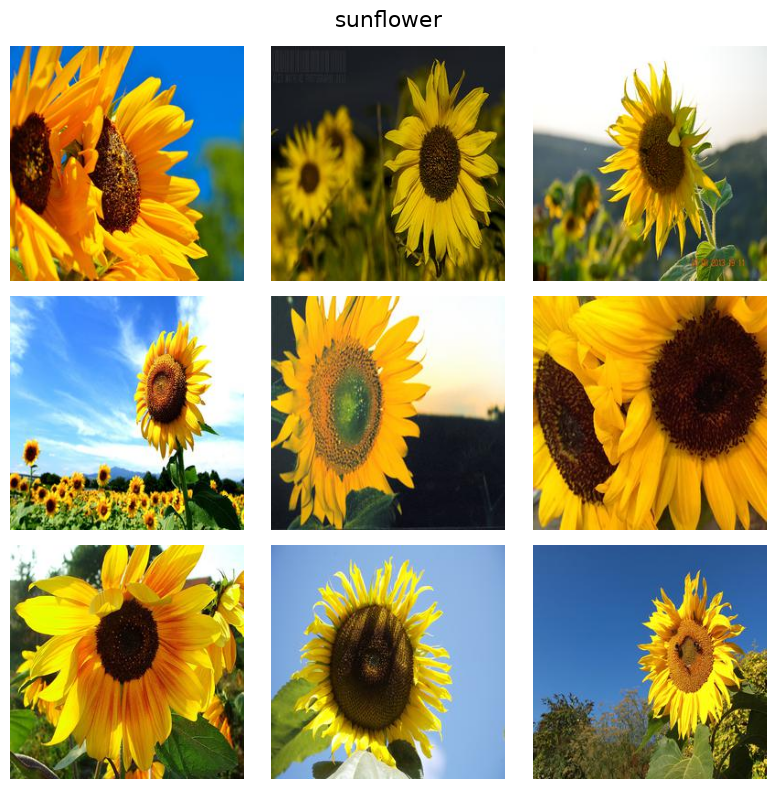

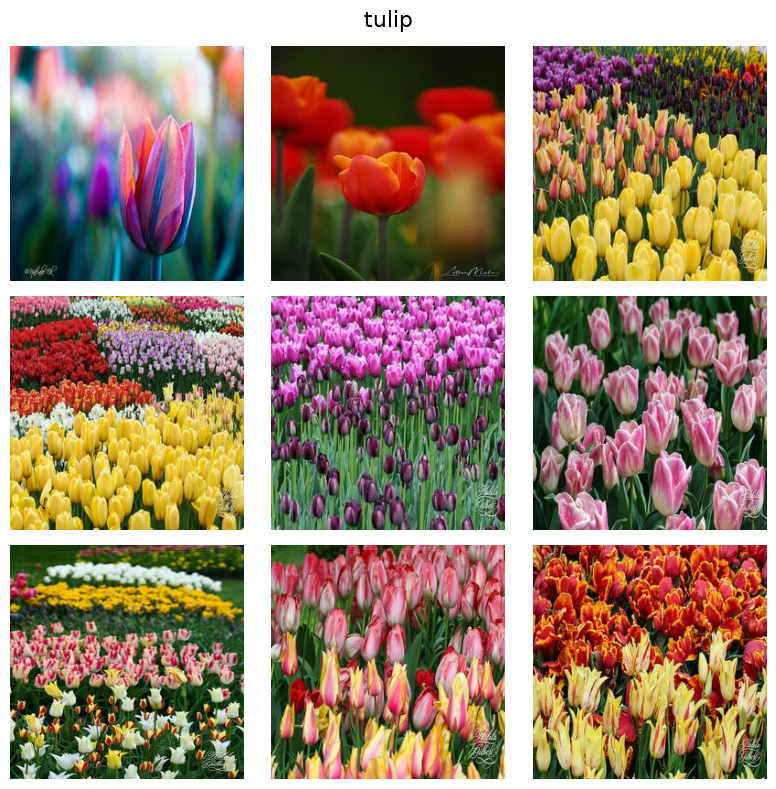

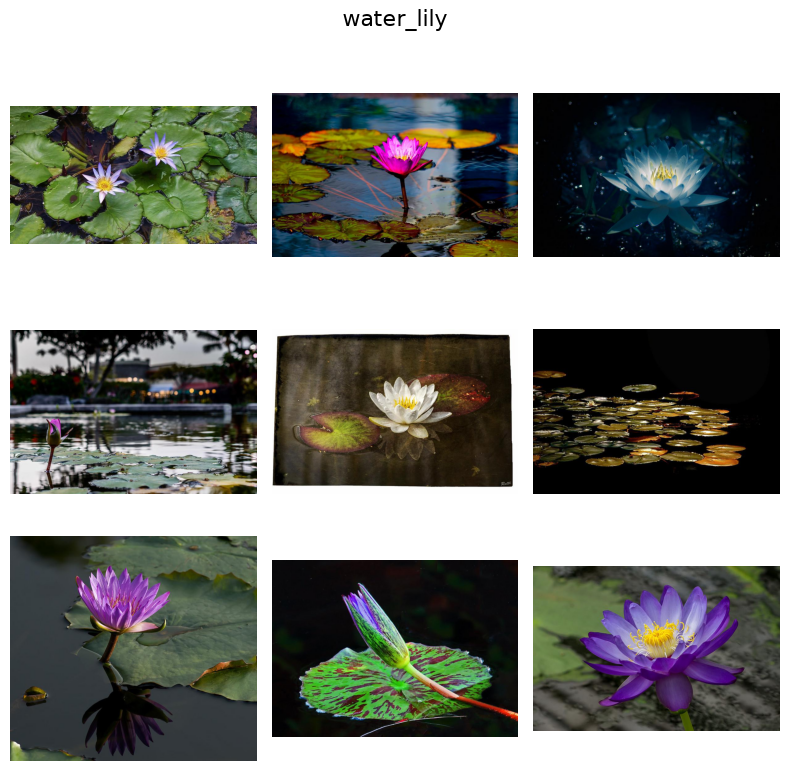

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

for class_name in class_names:
    class_dir = os.path.join(data_dir, class_name)
    image_files = os.listdir(class_dir)[:n_images]

    fig, axes = plt.subplots(3, 3, figsize=(8, 8))
    fig.suptitle(class_name, fontsize=16)

    for ax, img_file in zip(axes.flatten(), image_files):
        img = mpimg.imread(os.path.join(class_dir, img_file))
        ax.imshow(img)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


- Some flowers can have the same colors, or can look similar
- The dandelian have many forms
- A lot of flowers can have the same kind of background
- Some flowers can have many colors too, or many forms

## Part 2: Model Architecture Design

In [ ]:
from tensorflow.keras import layers, models

def build_model():
    num_classes = len(class_names)
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
    return models.Sequential([
        layers.Rescaling(1./255, input_shape=(180, 180, 3)),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax")
    ])


- 4 conv2d: standard use
- BatchNormalization after each conv2d: stabilize the learning
- Dense 256: enough to combine each features
- Dropout: minimize the overfitting

## Part 3: Hyperparameter Tuning

In [5]:
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import tensorflow as tf
import json
import gc

OPTIMIZERS = {
    "adam": Adam,
    "sgd": SGD,
    "rmsprop": RMSprop,
}

learning_rates = [1e-2, 1e-3]
batch_sizes = [32, 64]

def train_model(optimizer="adam", learning_rate=1e-3, batch_size=32, is_early_stop = False, is_reduce_lr = False):
    tf.keras.backend.clear_session()
    gc.collect()
    
    opt = OPTIMIZERS[optimizer](learning_rate=learning_rate)
    
    model = build_model()
    model.compile(
        optimizer=opt,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    train_ds_batched = train_ds.unbatch().batch(batch_size)
    val_ds_batched = val_ds.unbatch().batch(batch_size)

    callbacks = []
    if is_early_stop:
        early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        callbacks.append(early_stop)
    if is_reduce_lr:
        reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
        callbacks.append(reduce_lr)

    print(f"---------------------------------------------")
    print(f"START TRAINING")
    print(f"Optimizer:{optimizer}\nLearning_rate:{learning_rate}\nBatch_size:{batch_size}")

    with tf.device('/GPU:0'):
        history = model.fit(
            train_ds_batched,
            validation_data=val_ds_batched,
            epochs=30,
            callbacks=callbacks
        )

    model.save(f"/mnt/c/Users/avigd/Desktop/GENAI/Week7/Day2/Exercices/model_flowers_{optimizer}_{learning_rate}_{batch_size}.keras")

    with open(f"history_flowers_{optimizer}_{learning_rate}_{batch_size}.json", "w") as f:
        json.dump(history.history, f)

    return history

In [6]:
# for opt in OPTIMIZERS:
#     for learning_rate in learning_rates:
#         for batch_size in batch_sizes:
#             train_model(opt, learning_rate, batch_size, True, True)

In [7]:
train_model("adam", 1e-2, 32, True, True)

/home/avigd/tf-gpu/lib/python3.14/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


---------------------------------------------
START TRAINING
Optimizer:adam
Learning_rate:0.01
Batch_size:32
Epoch 1/30


/home/avigd/tf-gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791279886.736868   64535 service.cc:154] XLA service 0x38f94da0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791279886.736904   64535 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6 (Driver: 13.4.0[617.14.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1791279886.790523   64535 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791279888.215046   64535 cuda_dnn.cc:442] Loaded cuDNN version 92600
W0000 00:00:1791279889.033752   64859 cuda_timer.cc:88] De

      5/Unknown 13s 31ms/step - accuracy: 0.1125 - loss: 4.9259

I0000 00:00:1791279896.733201   64535 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1791279896.779568   64535 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791279884466577103 in buffer 'inject/prefetch_BatchDatasetV2/_23' sat unconsumed for 12.2858 seconds!


427/427 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.1096 - loss: 14.0656 - val_accuracy: 0.0816 - val_loss: 14.8023 - learning_rate: 0.0100
Epoch 2/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.1225 - loss: nan - val_accuracy: 0.1327 - val_loss: 13.9800 - learning_rate: 0.0100
Epoch 3/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.1244 - loss: nan - val_accuracy: 0.1327 - val_loss: 13.9800 - learning_rate: 0.0100
Epoch 4/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.1228 - loss: nan - val_accuracy: 0.1327 - val_loss: nan - learning_rate: 0.0100
Epoch 5/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.1177 - loss: 14.2206 - val_accuracy: 0.1224 - val_loss: 14.1445 - learning_rate: 0.0050
Epoch 6/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.1149 - loss: nan - val_accuracy: 0.1429 - val_loss: 13.8155 - learning_rate: 0.0050
Epoch 7/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.1138 - loss: 14.2844 - val_

In [8]:
train_model("adam", 1e-2, 64, True, True)

---------------------------------------------
START TRAINING
Optimizer:adam
Learning_rate:0.01
Batch_size:64
Epoch 1/30


I0000 00:00:1791280053.197287   66925 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_6', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1791280053.751145   66931 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1791280054.856529   66935 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 16 bytes spill stores, 16 bytes spill loads

I0000 00:00:1791280055.358354   66938 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_4', 8 bytes spill stores, 8 bytes spill loads



      4/Unknown 14s 53ms/step - accuracy: 0.0391 - loss: 5.2421

W0000 00:00:1791280060.772813   64535 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791280047258185454 in buffer 'inject/prefetch_BatchDatasetV2/_23' sat unconsumed for 13.4806 seconds!


214/214 ━━━━━━━━━━━━━━━━━━━━ 34s 95ms/step - accuracy: 0.0874 - loss: 14.0764 - val_accuracy: 0.1327 - val_loss: 13.9800 - learning_rate: 0.0100
Epoch 2/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.1204 - loss: 14.1760 - val_accuracy: 0.0918 - val_loss: 14.6379 - learning_rate: 0.0100
Epoch 3/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.1116 - loss: 14.3187 - val_accuracy: 0.1224 - val_loss: 14.1445 - learning_rate: 0.0100
Epoch 4/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.1127 - loss: 14.3021 - val_accuracy: 0.1224 - val_loss: 14.1445 - learning_rate: 0.0050
Epoch 5/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.1121 - loss: 14.3116 - val_accuracy: 0.1224 - val_loss: 14.1445 - learning_rate: 0.0050
Epoch 6/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.1149 - loss: 14.2647 - val_accuracy: 0.1327 - val_loss: 13.9800 - learning_rate: 0.0025


In [9]:
train_model("adam", 1e-3, 32, True, True)

---------------------------------------------
START TRAINING
Optimizer:adam
Learning_rate:0.001
Batch_size:32
Epoch 1/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 26s 45ms/step - accuracy: 0.2158 - loss: 3.1082 - val_accuracy: 0.2347 - val_loss: 2.3799 - learning_rate: 0.0010
Epoch 2/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.3053 - loss: 2.0000 - val_accuracy: 0.4184 - val_loss: 1.6887 - learning_rate: 0.0010
Epoch 3/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.3626 - loss: 1.8101 - val_accuracy: 0.4592 - val_loss: 1.6292 - learning_rate: 0.0010
Epoch 4/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.4059 - loss: 1.6771 - val_accuracy: 0.4796 - val_loss: 1.7010 - learning_rate: 0.0010
Epoch 5/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.4613 - loss: 1.5062 - val_accuracy: 0.4694 - val_loss: 1.3226 - learning_rate: 0.0010
Epoch 6/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.5077 - loss: 1.3903 - val_accuracy: 0.5408 - val_los

In [10]:
train_model("adam", 1e-3, 64, True, True)

---------------------------------------------
START TRAINING
Optimizer:adam
Learning_rate:0.001
Batch_size:64
Epoch 1/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 26s 92ms/step - accuracy: 0.2518 - loss: 2.9981 - val_accuracy: 0.1633 - val_loss: 2.7203 - learning_rate: 0.0010
Epoch 2/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.3755 - loss: 1.8197 - val_accuracy: 0.2143 - val_loss: 2.9748 - learning_rate: 0.0010
Epoch 3/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.4513 - loss: 1.5997 - val_accuracy: 0.4592 - val_loss: 1.5227 - learning_rate: 0.0010
Epoch 4/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.5134 - loss: 1.4090 - val_accuracy: 0.5204 - val_loss: 1.6215 - learning_rate: 0.0010
Epoch 5/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.5562 - loss: 1.2705 - val_accuracy: 0.5000 - val_loss: 1.4381 - learning_rate: 0.0010
Epoch 6/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step - accuracy: 0.5889 - loss: 1.1660 - val_accuracy: 0.5510 - val_los

In [11]:
train_model("sgd", 1e-2, 32, True, True)

---------------------------------------------
START TRAINING
Optimizer:sgd
Learning_rate:0.01
Batch_size:32
Epoch 1/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 22s 41ms/step - accuracy: 0.3634 - loss: 2.0426 - val_accuracy: 0.3367 - val_loss: 1.8290 - learning_rate: 0.0100
Epoch 2/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.5066 - loss: 1.4476 - val_accuracy: 0.4898 - val_loss: 1.8384 - learning_rate: 0.0100
Epoch 3/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.5748 - loss: 1.2358 - val_accuracy: 0.3980 - val_loss: 2.1664 - learning_rate: 0.0100
Epoch 4/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.6627 - loss: 0.9799 - val_accuracy: 0.5816 - val_loss: 1.0998 - learning_rate: 0.0050
Epoch 5/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.7028 - loss: 0.8637 - val_accuracy: 0.7041 - val_loss: 0.9191 - learning_rate: 0.0050
Epoch 6/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.7253 - loss: 0.7826 - val_accuracy: 0.5816 - val_loss:

In [12]:
train_model("sgd", 1e-2, 64, True, True)

---------------------------------------------
START TRAINING
Optimizer:sgd
Learning_rate:0.01
Batch_size:64
Epoch 1/30
    214/Unknown 20s 66ms/step - accuracy: 0.3673 - loss: 2.0996

W0000 00:00:1791281081.326830   64535 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 24886784 bytes after encountering the first element of size 24886784 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


214/214 ━━━━━━━━━━━━━━━━━━━━ 22s 76ms/step - accuracy: 0.3673 - loss: 2.0996 - val_accuracy: 0.1122 - val_loss: 5.5952 - learning_rate: 0.0100
Epoch 2/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.5270 - loss: 1.3964 - val_accuracy: 0.3980 - val_loss: 1.8555 - learning_rate: 0.0100
Epoch 3/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.6044 - loss: 1.1707 - val_accuracy: 0.4694 - val_loss: 1.6902 - learning_rate: 0.0100
Epoch 4/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.6505 - loss: 1.0184 - val_accuracy: 0.2551 - val_loss: 3.2620 - learning_rate: 0.0100
Epoch 5/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.6956 - loss: 0.8886 - val_accuracy: 0.5510 - val_loss: 1.4310 - learning_rate: 0.0100
Epoch 6/30


W0000 00:00:1791281128.394825   64535 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 24886784 bytes after encountering the first element of size 24886784 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.7294 - loss: 0.7816 - val_accuracy: 0.5918 - val_loss: 1.5042 - learning_rate: 0.0100
Epoch 7/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.7679 - loss: 0.6691 - val_accuracy: 0.4490 - val_loss: 2.3090 - learning_rate: 0.0100
Epoch 8/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.8210 - loss: 0.5295 - val_accuracy: 0.6122 - val_loss: 1.0586 - learning_rate: 0.0050
Epoch 9/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.8456 - loss: 0.4555 - val_accuracy: 0.6327 - val_loss: 0.9847 - learning_rate: 0.0050
Epoch 10/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.8567 - loss: 0.4162 - val_accuracy: 0.6633 - val_loss: 1.1260 - learning_rate: 0.0050
Epoch 11/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.8703 - loss: 0.3759 - val_accuracy: 0.4592 - val_loss: 2.4921 - learning_rate: 0.0050
Epoch 12/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.8917 - loss: 0.3

W0000 00:00:1791281276.985353   64535 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 24886784 bytes after encountering the first element of size 24886784 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.9345 - loss: 0.2073 - val_accuracy: 0.7653 - val_loss: 0.7578 - learning_rate: 0.0025
Epoch 20/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9395 - loss: 0.1993 - val_accuracy: 0.7551 - val_loss: 0.7912 - learning_rate: 0.0025
Epoch 21/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.9433 - loss: 0.1928 - val_accuracy: 0.7449 - val_loss: 0.8408 - learning_rate: 0.0012
Epoch 22/30
  3/214 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - accuracy: 0.9427 - loss: 0.1914

W0000 00:00:1791281311.723838   64535 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 24886784 bytes after encountering the first element of size 24886784 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.9444 - loss: 0.1860 - val_accuracy: 0.7449 - val_loss: 0.8015 - learning_rate: 0.0012
Epoch 23/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.9501 - loss: 0.1752 - val_accuracy: 0.7959 - val_loss: 0.7057 - learning_rate: 6.2500e-04
Epoch 24/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.9493 - loss: 0.1730 - val_accuracy: 0.7857 - val_loss: 0.6955 - learning_rate: 6.2500e-04
Epoch 25/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9532 - loss: 0.1673 - val_accuracy: 0.7959 - val_loss: 0.7088 - learning_rate: 6.2500e-04
Epoch 26/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.9532 - loss: 0.1631 - val_accuracy: 0.8163 - val_loss: 0.6919 - learning_rate: 6.2500e-04
Epoch 27/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step - accuracy: 0.9507 - loss: 0.1655 - val_accuracy: 0.7959 - val_loss: 0.6869 - learning_rate: 6.2500e-04
Epoch 28/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accur

W0000 00:00:1791281417.954501   64535 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 24886784 bytes after encountering the first element of size 24886784 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


In [13]:
train_model("sgd", 1e-3, 32, True, True)

---------------------------------------------
START TRAINING
Optimizer:sgd
Learning_rate:0.001
Batch_size:32
Epoch 1/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 22s 42ms/step - accuracy: 0.3126 - loss: 2.2654 - val_accuracy: 0.3367 - val_loss: 1.8326 - learning_rate: 0.0010
Epoch 2/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.4538 - loss: 1.6151 - val_accuracy: 0.4796 - val_loss: 1.3198 - learning_rate: 0.0010
Epoch 3/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.5203 - loss: 1.4253 - val_accuracy: 0.5204 - val_loss: 1.1956 - learning_rate: 0.0010
Epoch 4/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.5619 - loss: 1.2876 - val_accuracy: 0.5408 - val_loss: 1.2651 - learning_rate: 0.0010
Epoch 5/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.6002 - loss: 1.1779 - val_accuracy: 0.5510 - val_loss: 1.2922 - learning_rate: 0.0010
Epoch 6/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.6354 - loss: 1.0780 - val_accuracy: 0.5204 - val_loss

In [16]:
train_model("sgd", 1e-3, 64, True, True)

---------------------------------------------
START TRAINING
Optimizer:sgd
Learning_rate:0.001
Batch_size:64
Epoch 1/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 21s 76ms/step - accuracy: 0.2633 - loss: 2.6090 - val_accuracy: 0.0918 - val_loss: 3.2367 - learning_rate: 0.0010
Epoch 2/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.4134 - loss: 1.7324 - val_accuracy: 0.3469 - val_loss: 1.9179 - learning_rate: 0.0010
Epoch 3/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.4864 - loss: 1.5269 - val_accuracy: 0.4796 - val_loss: 1.4711 - learning_rate: 0.0010
Epoch 4/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.5305 - loss: 1.3981 - val_accuracy: 0.4388 - val_loss: 1.4522 - learning_rate: 0.0010
Epoch 5/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.5633 - loss: 1.2821 - val_accuracy: 0.5408 - val_loss: 1.2837 - learning_rate: 0.0010
Epoch 6/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.5969 - loss: 1.1990 - val_accuracy: 0.5000 - val_loss

In [17]:
train_model("rmsprop", 1e-2, 32, True, True)

---------------------------------------------
START TRAINING
Optimizer:rmsprop
Learning_rate:0.01
Batch_size:32
Epoch 1/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 23s 43ms/step - accuracy: 0.0713 - loss: 14.6235 - val_accuracy: 0.0714 - val_loss: 14.9668 - learning_rate: 0.0100
Epoch 2/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.0704 - loss: 14.9815 - val_accuracy: 0.0714 - val_loss: 14.9668 - learning_rate: 0.0100
Epoch 3/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.0762 - loss: 14.8879 - val_accuracy: 0.1224 - val_loss: 14.1445 - learning_rate: 0.0100
Epoch 4/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.0937 - loss: 14.6054 - val_accuracy: 0.1020 - val_loss: 14.4734 - learning_rate: 0.0100
Epoch 5/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.0918 - loss: 14.6358 - val_accuracy: 0.1224 - val_loss: 14.1445 - learning_rate: 0.0100
Epoch 6/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.1101 - loss: 14.3435 - val_accuracy: 0.1

In [18]:
train_model("rmsprop", 1e-2, 64, True, True)

---------------------------------------------
START TRAINING
Optimizer:rmsprop
Learning_rate:0.01
Batch_size:64
Epoch 1/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 22s 81ms/step - accuracy: 0.0765 - loss: 14.3411 - val_accuracy: 0.0714 - val_loss: 14.9668 - learning_rate: 0.0100
Epoch 2/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.0765 - loss: 14.8815 - val_accuracy: 0.0918 - val_loss: 14.6379 - learning_rate: 0.0100
Epoch 3/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.0999 - loss: 14.5038 - val_accuracy: 0.0714 - val_loss: 14.9668 - learning_rate: 0.0100
Epoch 4/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.0929 - loss: 14.6181 - val_accuracy: 0.0816 - val_loss: 14.8023 - learning_rate: 0.0100
Epoch 5/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.1059 - loss: 14.4060 - val_accuracy: 0.0816 - val_loss: 14.8023 - learning_rate: 0.0050
Epoch 6/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.1044 - loss: 14.4325 - val_accuracy: 0.1

In [19]:
train_model("rmsprop", 1e-3, 32, True, True)

---------------------------------------------
START TRAINING
Optimizer:rmsprop
Learning_rate:0.001
Batch_size:32
Epoch 1/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 22s 41ms/step - accuracy: 0.2302 - loss: 5.3972 - val_accuracy: 0.2653 - val_loss: 2.0503 - learning_rate: 0.0010
Epoch 2/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.3351 - loss: 2.6225 - val_accuracy: 0.3163 - val_loss: 1.9282 - learning_rate: 0.0010
Epoch 3/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.3879 - loss: 2.2682 - val_accuracy: 0.4184 - val_loss: 1.8841 - learning_rate: 0.0010
Epoch 4/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.4048 - loss: 2.0107 - val_accuracy: 0.4286 - val_loss: 1.5534 - learning_rate: 0.0010
Epoch 5/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.4269 - loss: 1.7290 - val_accuracy: 0.2449 - val_loss: 3.4260 - learning_rate: 0.0010
Epoch 6/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.4422 - loss: 1.7065 - val_accuracy: 0.4082 - val_

In [20]:
train_model("rmsprop", 1e-3, 64, True, True)

---------------------------------------------
START TRAINING
Optimizer:rmsprop
Learning_rate:0.001
Batch_size:64
Epoch 1/30
    214/Unknown 20s 70ms/step - accuracy: 0.2295 - loss: 7.3414

W0000 00:00:1791283087.051932   64535 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 24886784 bytes after encountering the first element of size 24886784 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


214/214 ━━━━━━━━━━━━━━━━━━━━ 22s 80ms/step - accuracy: 0.2295 - loss: 7.3414 - val_accuracy: 0.1429 - val_loss: 2.7996 - learning_rate: 0.0010
Epoch 2/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.3217 - loss: 2.7741 - val_accuracy: 0.2041 - val_loss: 2.5775 - learning_rate: 0.0010
Epoch 3/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.4064 - loss: 2.0625 - val_accuracy: 0.3469 - val_loss: 1.9684 - learning_rate: 0.0010
Epoch 4/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.4635 - loss: 1.8828 - val_accuracy: 0.4796 - val_loss: 1.6576 - learning_rate: 0.0010
Epoch 5/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.4741 - loss: 1.9375 - val_accuracy: 0.2959 - val_loss: 3.0030 - learning_rate: 0.0010
Epoch 6/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.5331 - loss: 1.4489 - val_accuracy: 0.3061 - val_loss: 4.1671 - learning_rate: 0.0010
Epoch 7/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.5971 - loss: 1.1951

Now we are searching the experiment that give the best performances, thats mean the best val accuracy and the valloss that not grow too much at the end of learning.
We conclude that the best parameters are with Adam, learning_rate=0.001 and batch_size=32, at epoch 19
- Epoch 19/30
- 427/427 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.8901 - loss: 0.3037 - val_accuracy: 0.8673 - val_loss: 0.4724 - learning_rate: 1.2500e-04
After that, the val loss increase, meaning of overfitting.

## Part 4: Data Augmentation

In [8]:
from tensorflow.keras import layers, models

def build_model():
    num_classes = len(class_names)
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
    return models.Sequential([
        layers.Rescaling(1./255, input_shape=(180, 180, 3)),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax")
    ])

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,

    rotation_range=45,
    # horizontal_flip=True,
    # vertical_flip=True,
    # zoom_range=0.2,
    # shear_range=0.2,

    # width_shift_range=0.2,
    # height_shift_range=0.2,
    # fill_mode="nearest"
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    "Data/train",
    target_size=(180, 180),
    batch_size=32,
    class_mode="categorical"
)

val_generator = val_datagen.flow_from_directory(
    "Data/val",
    target_size=(180, 180),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 13642 images belonging to 14 classes.
Found 98 images belonging to 14 classes.


In [12]:
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import tensorflow as tf
import json
import gc

OPTIMIZERS = {
    "adam": Adam,
    "sgd": SGD,
    "rmsprop": RMSprop,
}

learning_rates = [1e-2, 1e-3]
batch_sizes = [32, 64]

def train_model_improved():
    tf.keras.backend.clear_session()
    gc.collect()
    
    opt = Adam(learning_rate=1e-3)
    
    model = build_model()
    model.compile(
        optimizer=opt,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    train_ds_batched = train_datagen.flow_from_directory(
        "Data/train",
        target_size=(180, 180),
        batch_size=32,
        class_mode="categorical"
    )

    val_ds_batched = val_datagen.flow_from_directory(
        "Data/val",
        target_size=(180, 180),
        batch_size=32,
        class_mode="categorical",
        shuffle=False
    )

    early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)

    print(f"---------------------------------------------")
    print(f"START TRAINING")
    print(f"Optimizer:adam\nLearning_rate:{1e-3}\nBatch_size:{32}")

    with tf.device('/GPU:0'):
        history = model.fit(
            train_ds_batched,
            validation_data=val_ds_batched,
            epochs=30,
            callbacks=[early_stop, reduce_lr]
        )

    model.save(f"/mnt/c/Users/avigd/Desktop/GENAI/Week7/Day2/Exercices/model_flowers_adam_1e-3_32.keras")

    with open(f"history_flowers_adam_1e-3_32.json", "w") as f:
        json.dump(history.history, f)

    return history

In [13]:
train_model_improved()

Found 13642 images belonging to 14 classes.
Found 98 images belonging to 14 classes.
---------------------------------------------
START TRAINING
Optimizer:adam
Learning_rate:0.001
Batch_size:32
Epoch 1/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 162s 368ms/step - accuracy: 0.2089 - loss: 3.3560 - val_accuracy: 0.0714 - val_loss: 10.1944 - learning_rate: 0.0010
Epoch 2/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 140s 328ms/step - accuracy: 0.2751 - loss: 2.0521 - val_accuracy: 0.3776 - val_loss: 1.7251 - learning_rate: 0.0010
Epoch 3/30
427/427 ━━━━━━━━━━━━━━━━━━━━ 146s 341ms/step - accuracy: 0.2963 - loss: 1.9330 - val_accuracy: 0.1122 - val_loss: 4.1657 - learning_rate: 0.0010
Epoch 4/30
264/427 ━━━━━━━━━━━━━━━━━━━━ 52s 322ms/step - accuracy: 0.3202 - loss: 1.8748

KeyboardInterrupt: 

These tests will take far too long to carry out, each one lasts over an hour, and there are five of them.

## Part 5: Performance Evaluation and Analysis

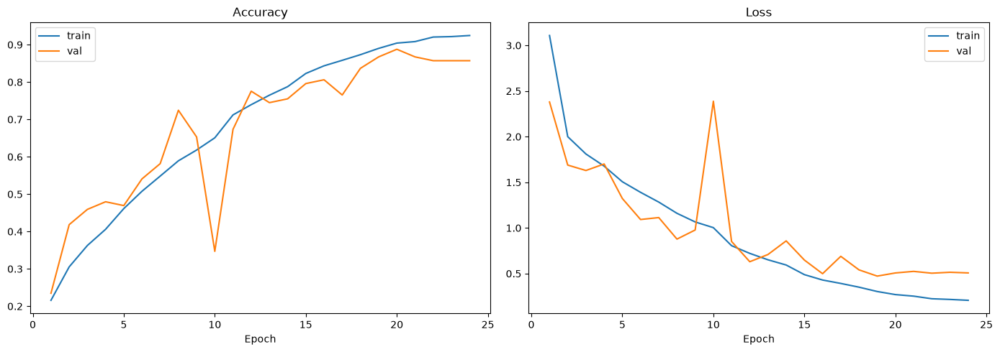

In [14]:
import json
import matplotlib.pyplot as plt

with open("histories/history_flowers_adam_0.001_32.json") as f:
    history = json.load(f)

epochs = range(1, len(history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["accuracy"], label="train")
axes[0].plot(epochs, history["val_accuracy"], label="val")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs, history["loss"], label="train")
axes[1].plot(epochs, history["val_loss"], label="val")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

We can see the val accuracy decreasing after 20 epochs, while the train accuracy still increasing: this is the sign of overfitting.
We can see the same behavior with the loss graph.

                  precision    recall  f1-score   support

         astilbe       0.80      0.57      0.67         7
      bellflower       0.78      1.00      0.88         7
black_eyed_susan       1.00      1.00      1.00         7
       calendula       0.71      0.71      0.71         7
california_poppy       1.00      0.71      0.83         7
       carnation       0.60      0.86      0.71         7
    common_daisy       0.86      0.86      0.86         7
       coreopsis       0.88      1.00      0.93         7
       dandelion       1.00      1.00      1.00         7
            iris       0.88      1.00      0.93         7
            rose       1.00      0.43      0.60         7
       sunflower       1.00      1.00      1.00         7
           tulip       0.88      1.00      0.93         7
      water_lily       1.00      1.00      1.00         7

        accuracy                           0.87        98
       macro avg       0.88      0.87      0.86        98
    weighted

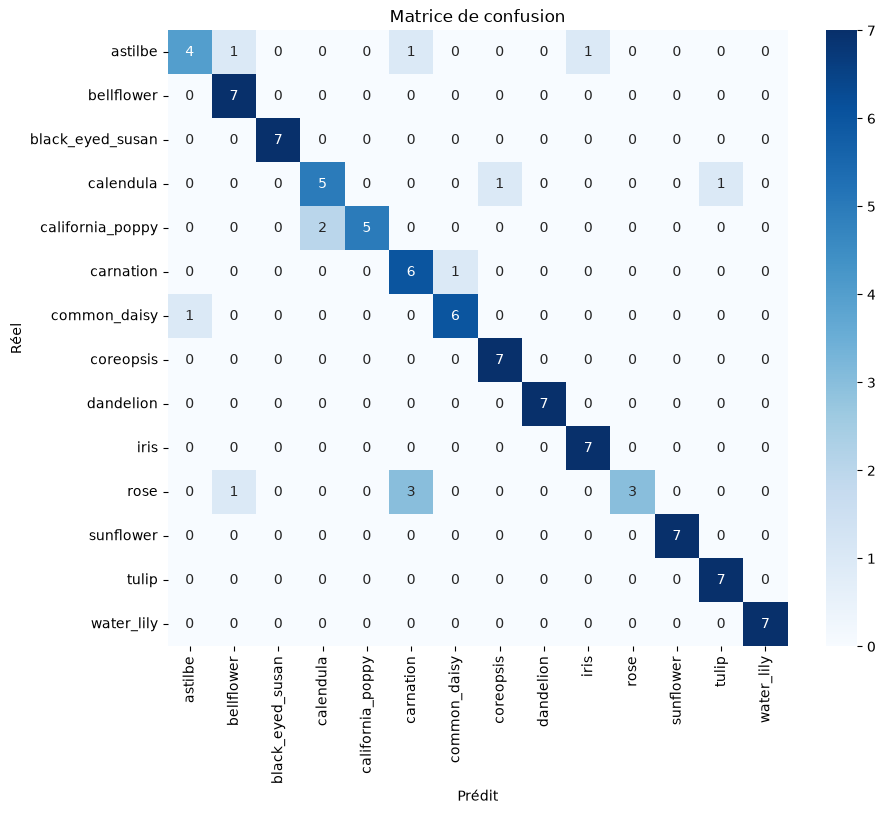

In [20]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model = tf.keras.models.load_model("models/model_flowers_adam_0.001_32.keras")

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion")
plt.show()

We can see that astilbe, calendula, carnation and rose, which the f-1 score are below 0.8, are the most difficult to classify.

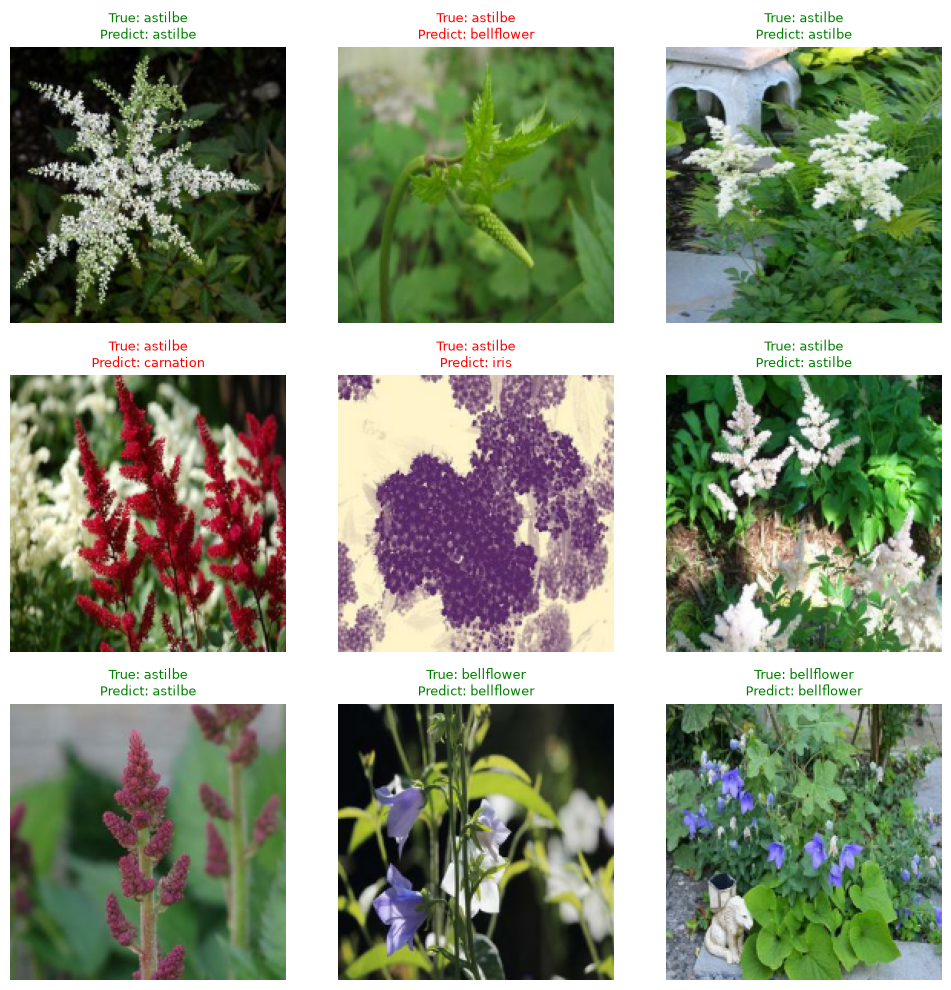

In [22]:
for images, labels in val_ds.take(1):
    preds = model.predict(images, verbose=0)
    true_idx = np.argmax(labels.numpy(), axis=1)
    pred_idx = np.argmax(preds, axis=1)

    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    for ax, img, t, p in zip(axes.flatten(), images, true_idx, pred_idx):
        ax.imshow(img.numpy().astype("uint8"))
        color = "green" if t == p else "red"
        ax.set_title(f"True: {class_names[t]}\nPredict: {class_names[p]}", color=color, fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

This result confirm our earlier conclusions.